In [52]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

In [53]:

emotion_dataset = load_dataset('dair-ai/emotion')
train_text      = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']


In [54]:
label_names = emotion_dataset['train'].features['label'].names

In [55]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [56]:
['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [57]:
df_train = pd.DataFrame(
    {
        'text'  : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text'  : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [58]:
df_train.isnull().sum()

,0
text,0
label,0


In [59]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

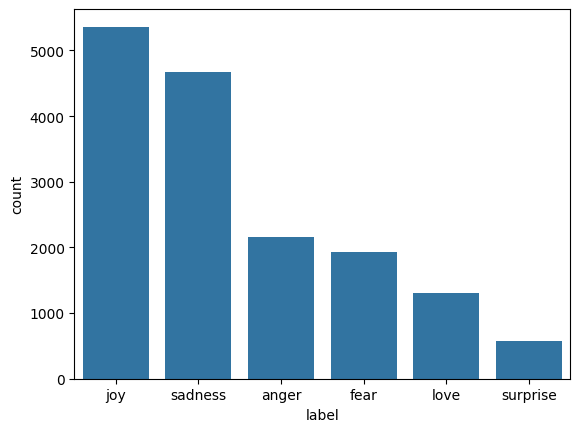

In [60]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [61]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [62]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000
tokenizer=Tokenizer(num_words=max_words,oov_token='unk')
tokenizer.fit_on_texts(df_train['text'])
train_sequences=tokenizer.texts_to_sequences(df_train['text'])
test_sequences=tokenizer.texts_to_sequences(df_test['text'])
padded_train_sequences=pad_sequences(train_sequences,maxlen=50,padding='post',truncating='post')
padded_test_sequences=pad_sequences(test_sequences,maxlen=50,padding='post',truncating='post')

In [63]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [64]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
               class_weight='balanced',
                classes=np.unique(train_label),
                y=train_label
            )
dict(enumerate(class_weights))


{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [65]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [66]:

import numpy as np
import tensorflow as tf

X_train = tf.convert_to_tensor(
    np.asarray(padded_train_sequences, dtype=np.int32)
)
X_test = tf.convert_to_tensor(
    np.asarray(padded_test_sequences, dtype=np.int32)
)
y_train = tf.convert_to_tensor(
    np.asarray(train_label, dtype=np.int32)
)
y_test = tf.convert_to_tensor(
    np.asarray(test_label, dtype=np.int32)
)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


(16000, 50) (16000,)
(2000, 50) (2000,)


### ***RNN***

In [67]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=6, activation='softmax')
])

rnn_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

rnn_model.build(input_shape=(None, 50))
rnn_model.summary()


history = rnn_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_test, y_test),
    batch_size=32,
    callbacks=[early_stopping]
)
rnn_loss, rnn_accuracy = rnn_model.evaluate(X_test,y_test )
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")



Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_20 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_20 (SimpleRNN)       │ (None, 50, 128)        │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_21 (SimpleRNN)       │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,325,638 (5.06 MB)

 Trainable params: 1,325,638 (5.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step - accuracy: 0.3040 - loss: 1.6679 - val_accuracy: 0.3475 - val_loss: 1.5785
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.3275 - loss: 1.5889 - val_accuracy: 0.3360 - val_loss: 1.5600
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.3674 - loss: 1.5600 - val_accuracy: 0.3430 - val_loss: 1.5875
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.4057 - loss: 1.5087 - val_accuracy: 0.3570 - val_loss: 1.5929
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 37ms/step - accuracy: 0.4643 - loss: 1.4192 - val_accuracy: 0.3645 - val_loss: 1.6224
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3360 - loss: 1.5600
RNN Loss: 1.5600439310073853
RNN Accuracy: 0.335999995470047


### ***lstm***

In [68]:
from tensorflow.keras.layers import LSTM
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128,input_length=50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=6, activation='softmax')
])

lstm_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

lstm_model.build(input_shape=(None, 50))
lstm_model.summary()


history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_test, y_test),
    batch_size=32,
    callbacks=[early_stopping]
)
lstm_loss, lstm_accuracy = lstm_model.evaluate(X_test,y_test )
print(f"lstm Loss: {lstm_loss}")
print(f"lstm Accuracy: {lstm_accuracy}")



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_21 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 50, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,461,382 (5.57 MB)

 Trainable params: 1,461,382 (5.57 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 49s 94ms/step - accuracy: 0.3228 - loss: 1.5981 - val_accuracy: 0.3475 - val_loss: 1.5638
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.3269 - loss: 1.5872 - val_accuracy: 0.3475 - val_loss: 1.5609
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 87s 94ms/step - accuracy: 0.3287 - loss: 1.5737 - val_accuracy: 0.2850 - val_loss: 1.4947
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 49s 98ms/step - accuracy: 0.3321 - loss: 1.5760 - val_accuracy: 0.3475 - val_loss: 1.5602
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 88ms/step - accuracy: 0.3406 - loss: 1.5208 - val_accuracy: 0.3975 - val_loss: 1.2997
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 88ms/step - accuracy: 0.4594 - loss: 1.1300 - val_accuracy: 0.5180 - val_loss: 1.0455
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 100s 124ms/step - accuracy: 0.5701 - loss: 0.8806 - val_accuracy: 0.5865 - val_loss: 0.8518
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 64s 88ms/step - accuracy: 0.6361 - loss: 0.7129 

### ***GRU***

In [69]:

from tensorflow.keras.layers import GRU

GRU_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=6, activation='softmax')
])

GRU_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

GRU_model.build(input_shape=(None, 50))
GRU_model.summary()


history = GRU_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_test, y_test),
    batch_size=32,
    callbacks=[early_stopping]
)
GRU_loss, GRU_accuracy = GRU_model.evaluate(X_test,y_test )
print(f"GRU Loss: {GRU_loss}")
print(f"GRU Accuracy: {GRU_accuracy}")



Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_22 (Embedding)        │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_8 (GRU)                     │ (None, 50, 128)        │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_9 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,416,710 (5.40 MB)

 Trainable params: 1,416,710 (5.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 63ms/step - accuracy: 0.3235 - loss: 1.5968 - val_accuracy: 0.3475 - val_loss: 1.5599
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 63ms/step - accuracy: 0.3257 - loss: 1.5844 - val_accuracy: 0.3475 - val_loss: 1.5600
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 64ms/step - accuracy: 0.3332 - loss: 1.5810 - val_accuracy: 0.3475 - val_loss: 1.5799
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.3475 - loss: 1.5599
GRU Loss: 1.5598877668380737
GRU Accuracy: 0.3474999964237213


### **ADVANCED GRU**

In [70]:
from tensorflow.keras.layers import Bidirectional
BIGRU_model = Sequential([
    Embedding(input_dim=max_words, output_dim=300),
    Bidirectional(GRU(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=6, activation='softmax')
])

BIGRU_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

BIGRU_model.summary()
BIGRU_model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_test, y_test),
    batch_size=32,
    callbacks=[early_stopping]
)
BIGRU_loss, BIGRU_accuracy = BIGRU_model.evaluate(X_test,y_test )
print(f"BIGRU Loss: {BIGRU_loss}")
print(f"BIGRRU Accuracy: {BIGRU_accuracy}")

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_23 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 92s 176ms/step - accuracy: 0.6659 - loss: 0.8892 - val_accuracy: 0.9035 - val_loss: 0.2344
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 89s 179ms/step - accuracy: 0.9309 - loss: 0.1960 - val_accuracy: 0.9310 - val_loss: 0.1655
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 85s 170ms/step - accuracy: 0.9536 - loss: 0.1213 - val_accuracy: 0.9310 - val_loss: 0.1770
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 90s 179ms/step - accuracy: 0.9702 - loss: 0.0838 - val_accuracy: 0.9300 - val_loss: 0.2279
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 153s 201ms/step - accuracy: 0.9730 - loss: 0.0741 - val_accuracy: 0.9110 - val_loss: 0.2508
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9310 - loss: 0.1655
BIGRU Loss: 0.16553397476673126
BIGRRU Accuracy: 0.9309999942779541


63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step


<Axes: >

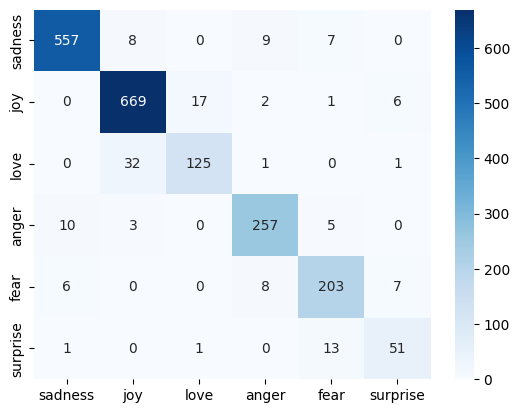

In [71]:
from sklearn.metrics import classification_report, confusion_matrix
BIGRU_pred = BIGRU_model.predict(X_test)
BIGRU_pred = np.argmax(BIGRU_pred, axis=1)
sns.heatmap(confusion_matrix(y_test, BIGRU_pred), annot=True, fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)


In [73]:
import os
import pickle

model="Artifical"
os.makedirs(model,exist_ok=True)
BIGRU_model.save(os.path.join(model,"BIGRU_model.keras"))
with open(os.path.join(model,'tokenizer.pkl'),'wb')as file:
  pickle.dump(tokenizer,file)